
# Day 01 — Brownian Motion

**Topic:** Stochastic Processes  
**Goal:** Understand and simulate standard Brownian motion using Python.

## 1. Definition

A standard Brownian motion (Wiener process) $(W_t)_{t \geq 0}$ satisfies:

1. $W_0 = 0$.
2. It has independent increments.
3. $W_t-W_s \sim \mathcal{N}(0,t-s)$ for $0 \leq s < t$.
4. Its sample paths are continuous almost surely.

Therefore,

$$
\mathbb{E}[W_t]=0,
\qquad
\operatorname{Var}(W_t)=t.
$$

## 2. Brownian Motion Simulation

Divide the time interval $[0,T]$ into $N$ steps:

$$
\Delta t = \frac{T}{N}.
$$

Brownian increments follow:

$$
\Delta W_t = W_{t+\Delta t}-W_t
\sim \mathcal{N}(0,\Delta t).
$$

Using $Z_t \sim \mathcal{N}(0,1)$:

$$
\boxed{\Delta W_t = \sqrt{\Delta t}\,Z_t}
$$

The simulation is constructed recursively:

$$
\boxed{W_{t+\Delta t}=W_t+\sqrt{\Delta t}\,Z_t}
$$

## 3. Why Square Root of Time?

Since $\operatorname{Var}(Z_t)=1$,

$$
\operatorname{Var}(\sqrt{\Delta t}\,Z_t)
=\Delta t.
$$

Using $\Delta t Z_t$ instead would give variance
$(\Delta t)^2$, which is incorrect.

## 4. Python Implementation

We simulate one Brownian motion path with:

- $T=1$ year
- $N=252$ time steps
- $W_0=0$

## 5. Key Observations

- Brownian motion has random, independent increments.
- Its expected value remains zero.
- Its variance increases linearly with time.
- Individual paths are continuous but nowhere differentiable almost surely.

## 6. Mini Exercise

1. Generate 10 independent Brownian motion paths.
2. Change $N$ from 252 to 1,000.
3. Estimate $\mathbb{E}[W_T]$ and $\operatorname{Var}(W_T)$ using 1,000 simulations.

**Expected theoretical results:**

$$
\mathbb{E}[W_T]=0,
\qquad
\operatorname{Var}(W_T)=T.
$$


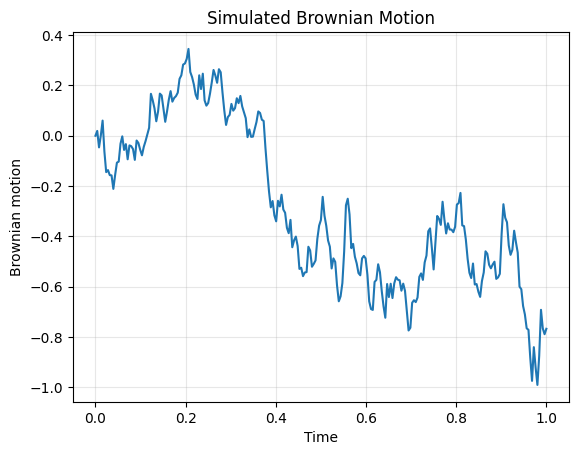

In [8]:
import numpy as np
import matplotlib.pyplot as plt

T = 1
N = 252
dt = T / N

rng = np.random.default_rng(42)  # Set a random seed for reproducibility

dW = np.sqrt(dt) * rng.normal(size=N)
W = np.insert(np.cumsum(dW), 0, 0)

t = np.linspace(0, T, N + 1)

plt.plot(t, W)
plt.xlabel("Time")
plt.ylabel("Brownian motion")
plt.title("Simulated Brownian Motion")
plt.grid(alpha=0.3)
plt.show()



# Day 02 — Quadratic Variation of Brownian Motion

## 1. Objective

In Day 1, we studied Brownian Motion and simulated its sample paths using Python.

Today, we focus on **Quadratic Variation**, an important concept that connects Brownian Motion to **Itô Calculus**.

By the end of this notebook, we should be able to:

- Understand the definition of quadratic variation.
- Explain why Brownian Motion has nonzero quadratic variation.
- Understand the stochastic calculus rule $(dW_t)^2 = dt$.
- Simulate quadratic variation using Python.
- Investigate numerical convergence as the number of time steps increases.

---

## 2. Mathematical Background

### 2.1 Brownian Motion

A standard Brownian Motion $(W_t)_{t \geq 0}$ satisfies:

1. $W_0 = 0$.
2. It has independent increments.
3. Its increments follow a normal distribution:

$$
W_t-W_s \sim \mathcal{N}(0,t-s), \qquad 0 \leq s < t.
$$

4. Its sample paths are continuous.

For a small time increment $\Delta t$:

$$
\Delta W_t \sim \mathcal{N}(0,\Delta t).
$$

Therefore, we can simulate increments using:

$$
\boxed{\Delta W_t = \sqrt{\Delta t}Z}
$$

where $Z \sim \mathcal{N}(0,1)$.

---

## 3. What Is Quadratic Variation?

Consider a partition of the time interval $[0,T]$:

$$
0=t_0<t_1<\cdots<t_n=T.
$$

The quadratic variation approximation is defined as:

$$
Q_n(T)=\sum_{i=0}^{n-1}
(W_{t_{i+1}}-W_{t_i})^2.
$$

This measures the accumulated squared increments of a stochastic process.

For Brownian Motion, as the partition becomes finer:

$$
\boxed{
Q_n(T)\xrightarrow{P}T
}
$$

provided that the maximum partition interval tends to zero.

Thus, the quadratic variation of Brownian Motion is:

$$
\boxed{[W]_T=T}
$$

### Interpretation

Even though Brownian Motion is continuous, its paths are extremely irregular.

Its increments may be positive or negative, but squaring them removes their signs.

As we divide time into smaller intervals, the sum of squared increments approaches the total elapsed time.

---

## 4. Why Does Quadratic Variation Equal $T$?

Recall:

$$
\Delta W_i \sim \mathcal{N}(0,\Delta t).
$$

Since Brownian increments have mean zero and variance $\Delta t$:

$$
\mathbb{E}[(\Delta W_i)^2]=\Delta t.
$$

For an equally spaced partition:

$$
\Delta t = \frac{T}{n}.
$$

The expected quadratic variation is:

$$
\begin{aligned}
\mathbb{E}[Q_n(T)]
&=\mathbb{E}\left[\sum_{i=0}^{n-1}(\Delta W_i)^2\right]\\
&=\sum_{i=0}^{n-1}\mathbb{E}[(\Delta W_i)^2]\\
&=\sum_{i=0}^{n-1}\Delta t\\
&=n\frac{T}{n}.
\end{aligned}
$$

Therefore:

$$
\boxed{\mathbb{E}[Q_n(T)]=T}
$$

**Important:** This establishes the expected value, not convergence by itself.

For equally spaced partitions, independence of Brownian increments gives:

$$
\operatorname{Var}(Q_n(T))
=2n(\Delta t)^2
=\frac{2T^2}{n}.
$$

As $n\to\infty$:

$$
\operatorname{Var}(Q_n(T))\to0.
$$

Consequently, $Q_n(T)$ converges to $T$ in mean square, and therefore in probability.

---

## 5. Connection to Itô Calculus

In ordinary calculus, terms of second order are usually neglected when deriving differential formulas.

However, Brownian Motion behaves differently.

Because:

$$
\Delta W_t \sim \mathcal{N}(0,\Delta t),
$$

its typical increment has size:

$$
\Delta W_t=O_p(\sqrt{\Delta t}).
$$

Consequently:

$$
(\Delta W_t)^2=O_p(\Delta t).
$$

This motivates the fundamental Itô calculus multiplication rules:

$$
\boxed{
\begin{aligned}
(dW_t)^2 &= dt,\\
dt\,dW_t &= 0,\\
(dt)^2 &= 0.
\end{aligned}
}
$$

These are symbolic rules for stochastic differentials, justified through quadratic variation.

### Why Is This Important?

For an Itô process:

$$
dX_t=\mu_t\,dt+\sigma_t\,dW_t,
$$

the quadratic differential is:

$$
\boxed{(dX_t)^2=\sigma_t^2\,dt.}
$$

This additional second-order term is the key difference between ordinary calculus and Itô calculus.

It leads directly to **Itô's Lemma**, which we will study in Day 3.

---

## 6. Numerical Experiment

### Experiment 1 — Simulating Quadratic Variation

We simulate a Brownian Motion path and calculate:

$$
Q_n(t)=\sum_{t_{i+1}\leq t}(\Delta W_i)^2.
$$

We then compare the simulated quadratic variation with its theoretical value:

$$
[W]_t=t.
$$

**Expected observation:**

As the number of time steps increases, the simulated quadratic variation should become closer to the theoretical line.

### Experiment 2 — Convergence Analysis

Repeat the simulation for:

$$
n \in \{10,100,1000,10000\}.
$$

Calculate the absolute error:

$$
\boxed{\text{Error}_n=|Q_n(T)-T|}
$$

For a single random path, the error is not guaranteed to decrease at every step.

To investigate convergence more reliably, repeat the experiment over many independent simulations.

The theoretical root mean squared error is:

$$
\boxed{
\operatorname{RMSE}(Q_n(T))
=T\sqrt{\frac{2}{n}}
}
$$

This suggests a convergence rate of order:

$$
O(n^{-1/2}).
$$

---

## 7. Questions for Understanding

**Q1.** Why does Brownian Motion have nonzero quadratic variation while a continuously differentiable function has zero quadratic variation?

**Q2.** Why do we square Brownian increments instead of summing their absolute values?

**Q3.** Explain the meaning of:

$$
(dW_t)^2=dt.
$$

**Q4.** What happens to the quadratic variation approximation as $n\to\infty$?

**Q5.** If:

$$
dX_t=0.05\,dt+0.2\,dW_t,
$$

what is $(dX_t)^2$?

---

## 8. Conclusion

Today, we learned that Brownian Motion has a unique mathematical property:

$$
\boxed{[W]_t=t}
$$

Unlike smooth deterministic functions, Brownian Motion accumulates nonzero quadratic variation.

This property explains why stochastic calculus requires additional differential rules:

$$
(dW_t)^2=dt.
$$

**Key takeaway:**

Quadratic variation is the mathematical foundation for the second-order correction term in Itô's Lemma.

### Next — Day 03

**Itô's Lemma: Theory, Derivation, and Python Verification**

We will study how to differentiate functions of stochastic processes and verify the results numerically.


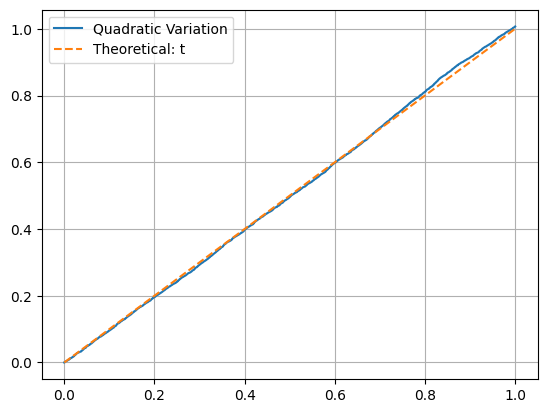

In [4]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

T = 1
n = 10000
dt = T / n

dW = np.sqrt(dt) * np.random.randn(n)
W = np.insert(np.cumsum(dW), 0, 0)

QV = np.insert(np.cumsum(dW**2), 0, 0)
t = np.linspace(0, T, n + 1)

plt.plot(t, QV, label="Quadratic Variation")
plt.plot(t, t, "--", label="Theoretical: t")
plt.legend()
plt.grid()
plt.show()